Group Project Part 2: Discovering Patterns in SLCM Community Needs
CS430 | Team members: Hana Abdelaal, Hanan Mohamed

How to use: click Run All (or run each cell from top to bottom). Put the 5 CSV files in the same folder as this notebook (in Colab: upload them with the folder icon on the left).

In [ ]:
#importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

In [ ]:
#load the data
profiles   = pd.read_csv("SLCM_part2_intake_profiles_clean.csv", dtype={"zip_code": str})
members    = pd.read_csv("SLCM_part2_household_members_clean.csv")
subs       = pd.read_csv("SLCM_part2_care_path_subtickets.csv")
dictionary = pd.read_csv("SLCM_part2_data_dictionary.csv")
cleaning_log = pd.read_csv("SLCM_part2_cleaning_log.csv")

print("Profiles:", profiles.shape, "| Members:", members.shape, "| Sub-tickets:", subs.shape)
print("Profiles + sub-tickets =", len(profiles) + len(subs), "(original file had 639 rows)")

Profiles: (426, 85) | Members: (993, 9) | Sub-tickets: (213, 10)
Profiles + sub-tickets = 639 (original file had 639 rows)


In [ ]:
print("Rows, columns:", profiles.shape)
profiles.head()

Rows, columns: (426, 85)


,issue_key,pid,pid_match_basis,issue_type,case_status,case_status_category,is_duplicate_ticket,created_date,intake_date,intake_month,...,hh_chronic_health,age_at_intake,gender,race_ethnicity,primary_language,primary_insurance,other_professionals_helping,utility_past_due,has_lge_account_on_file,has_water_account_on_file
0,NEIG-19349,P0289,Name + DOB,New Profile,Initial Contact,In Progress,No,2026-08-12,2026-08-12,2026-08,...,0,24.0,Woman,Black or African American,English,Medicaid,No,Not recorded,No,No
1,NEIG-19336,P0352,Name + DOB,New Profile,Second Contact,In Progress,No,2026-08-12,2026-08-12,2026-08,...,0,42.0,Woman,NaN,English,NaN,No,LG&E,Yes,Yes
2,NEIG-19324,P0308,Name + DOB,New Profile,Initial Contact,In Progress,No,2026-08-12,2026-08-12,2026-08,...,0,40.0,Man,Black or African American,English,Medicaid,No,LG&E,Yes,Yes
3,NEIG-19311,P0253,Name + DOB,New Profile,Second Contact,In Progress,No,2026-08-11,2026-08-11,2026-08,...,1,41.0,Woman,Black or African American,English,Medicaid,No,LG&E,Yes,No
4,NEIG-19296,P0102,Name + DOB,New Profile,Initial Contact,In Progress,No,2026-08-11,2026-08-11,2026-08,...,0,29.0,Woman,White,English,Medicaid,Yes,Not recorded,No,No


In [ ]:
# Look at the columns we plan to use before relying on them
key_cols = ["pid", "pid_ticket_seq", "is_duplicate_ticket", "income_monthly", "children_17_under",
            "household_size_from_members", "housing_group", "eviction_status", "employment_status",
            "past_due_rent", "urgent_housing_proxy"]
print(profiles[key_cols].dtypes)
print()
print("Missing values in these columns:")
print(profiles[key_cols].isna().sum())

pid                             object
pid_ticket_seq                   int64
is_duplicate_ticket             object
income_monthly                 float64
children_17_under                int64
household_size_from_members      int64
housing_group                   object
eviction_status                 object
employment_status               object
past_due_rent                  float64
urgent_housing_proxy            object
dtype: object

Missing values in these columns:
pid                              0
pid_ticket_seq                   0
is_duplicate_ticket              0
income_monthly                   0
children_17_under                0
household_size_from_members      0
housing_group                    0
eviction_status                  0
employment_status                0
past_due_rent                  263
urgent_housing_proxy             0
dtype: int64


In [ ]:
for col in ["is_duplicate_ticket", "housing_group", "eviction_status", "employment_status"]:
    print(profiles[col].value_counts(dropna=False), "\n")

is_duplicate_ticket
No     414
Yes     12
Name: count, dtype: int64 

housing_group
Renting, behind           234
Renting, current          126
Doubled up / temporary     32
Unhoused                   15
Other                      10
Own home                    9
Name: count, dtype: int64 

eviction_status
Not being evicted          255
Currently being evicted    108
Unknown                     63
Name: count, dtype: int64 

employment_status
Unemployed but want to find work                       195
Employed                                               118
Employed, but need more hours and/or different work     57
Other                                                   29
Unemployed and not looking for work                     27
Name: count, dtype: int64 



In [ ]:
print(profiles["income_monthly"].describe().round(0))
print("Income = $0:", (profiles["income_monthly"] == 0).sum(), "of", len(profiles))
print("Tickets per person:"); print(profiles.groupby("pid").size().value_counts().sort_index())

count     426.0
mean     1172.0
std      1268.0
min         0.0
25%         0.0
50%       907.0
75%      2000.0
max      9000.0
Name: income_monthly, dtype: float64
Income = $0: 136 of 426
Tickets per person:
1    368
2     24
3      2
4      1
Name: count, dtype: int64


In [ ]:
pd.set_option("display.max_colwidth", 120)
dictionary[["column", "role", "description", "pct_missing"]]

,column,role,description,pct_missing
0,issue_key,Identifier / structure - never a clustering input,Jira ticket number (NEIG-#####); one row per profile ticket,0.0
1,pid,Identifier / structure - never a clustering input,Approximate person ID built by name matching; links repeat tickets,0.0
2,pid_match_basis,Data-quality flag,How PID was matched; all profile tickets are 'Name + DOB' (name-only matches occur on sub-tickets),0.0
3,issue_type,Identifier / structure - never a clustering input,New Profile / Connected Neighbor Profile / Flourishing Neighbor Profile,0.0
4,case_status,"Context - use to profile clusters, not as input","Jira workflow status at export (e.g. Referral Only, Goal Attained). Process status, not a family outcome",0.0
...,...,...,...,...
80,primary_insurance,"Context - use to profile clusters, not as input",Medicaid / Employee-coverage / Medicare / Other,8.2
81,other_professionals_helping,"Context - use to profile clusters, not as input",Other professionals already helping with goals,0.0
82,utility_past_due,Need indicator - candidate feature,LG&E / Water / Don't know / Not recorded. 'Not recorded' is not 'No',0.0
83,has_lge_account_on_file,"Context - use to profile clusters, not as input",An LG&E account is on file for this person,0.0


In [ ]:
#read cleaning log
cleaning_log[["step", "field", "rule", "rows_affected"]]

,step,field,rule,rows_affected
0,0,(file),"Loaded 639 rows x 93 cols (intake), 993 rows (members)",639
1,1,Issue Type,Profile tickets (New / Connected / Flourishing Neighbor Profile) -> profiles file; all other Issue Types -> care-pat...,213
2,1,Parent key,Sub-tickets whose parent ticket is not in the export kept in sub-ticket file with parent_in_file = No,13
3,2,PID (sub-tickets),Added pid_matches_parent: sub-ticket PID differs from its parent profile's PID,31
4,3,Status,Status == 'Duplicate' flagged in is_duplicate_ticket (not removed),12
5,3,Created / Intake Date,Parsed 'dd/Mon/yy h:mm AM' text to ISO dates; added intake_month,426
6,3,PID,"Added pid_n_profile_tickets, pid_ticket_seq (1 = earliest), pid_is_latest_profile, pid_n_all_tickets (profiles + sub...",426
7,3,(sub-tickets),Counted linked care-path sub-tickets per profile: n_care_path_subtickets and sub_<group> counts,165
8,4,Zip Code,Kept first 5 digits of ZIP+4 values (e.g. 40214-5715 -> 40214),5
9,4,Zip Code,Non-numeric ZIP '402q1' set to missing,1


Task 0:

### Task 0: Analysis Unit

For this project, we chose to analyze one record per person (PID) instead of one record per intake ticket. The original dataset contains 426 intake profiles representing 395 PIDs. Some individuals have multiple tickets. For each person we kept their most recent ticket that was not flagged as a duplicate (using pid_ticket_seq and is_duplicate_ticket). Six duplicate-flagged tickets remain because those people have no other ticket; they are kept and flagged.

This approach helps prevent individuals with multiple tickets from having more influence on the clustering results. Our goal is to identify patterns of community needs rather than patterns of repeated paperwork.

### Part 1 Findings and Data Quality

In Part 1, we found that 28.2% of the intake profiles showed an active housing or eviction crisis. We also discovered that employment did not always mean financial stability. Employed households had a median income of $2,000, but 30.9% still reported receiving food benefits.

One important data-quality limitation was missing or unknown information. For example, 63 records had an eviction status of "Unknown." We also found repeated PIDs because some individuals contacted SLCM more than once.

These findings influenced our Part 2 approach. We included housing, eviction, employment, and income information in our clustering analysis. We also kept unknown values separate from confirmed statuses and used the latest profile for each PID to avoid counting the same person multiple times.

In [ ]:
# ---- ANALYSIS UNIT: one row per person (PID) ----
# Mark tickets that staff flagged as duplicates (1 = duplicate, 0 = not)
profiles["is_dup"] = (profiles["is_duplicate_ticket"] == "Yes").astype(int)

# Sort so each person's best ticket comes first: non-duplicates first, then the newest
ordered = profiles.sort_values(["pid", "is_dup", "pid_ticket_seq"],
                               ascending=[True, True, False])

# Keep only the first (best) ticket for each person
analysis = ordered.drop_duplicates(subset="pid", keep="first").reset_index(drop=True)

print("Tickets:", len(profiles))
print("People (PIDs):", profiles["pid"].nunique())
print("Rows kept:", len(analysis))
print("Duplicate-flagged tickets still in the table:", analysis["is_dup"].sum())

Tickets: 426
People (PIDs): 395
Rows kept: 395
Duplicate-flagged tickets still in the table: 6


In [ ]:
analysis.loc[analysis["is_dup"] == 1,
             ["pid", "is_duplicate_ticket", "pid_ticket_seq"]]

,pid,is_duplicate_ticket,pid_ticket_seq
11,P0012,Yes,1
38,P0039,Yes,1
54,P0055,Yes,1
78,P0079,Yes,1
370,P0372,Yes,1
380,P0382,Yes,1


### Task 1: Feature Selection

For our clustering analysis, we selected six features to understand different community needs: monthly income, number of children, household size, housing status, eviction status, and employment status.

We selected these features because they help describe the financial, housing, and household circumstances of people seeking assistance from SLCM.

Monthly income was transformed using log(1 + income) to reduce the influence of very high incomes while keeping reported $0 incomes as valid values. We excluded past-due rent from clustering because too many records were missing this information. However, we can still use it to describe the clusters afterward.

### Feature Table

| Feature | Missing Values | Preparation | Reason |
|---|---|---|---|
| Monthly income | 0 | Log(1 + income), standardized | Measures financial circumstances |
| Children 17 and under | 0 | Median imputation, standardized | Describes children in the household |
| Household size | 0 | Median imputation, standardized | Measures household composition |
| Housing status | 0 | One-hot encoding | Describes housing circumstances |
| Eviction status | 0 | One-hot encoding | Describes eviction circumstances |
| Employment status | 0 | One-hot encoding | Describes employment circumstances |

### Data Cleaning and Preprocessing Decisions

We started with 426 intake profiles representing 395 unique PIDs. We selected the latest available profile for each PID to avoid counting repeated contacts as separate people.

We used six features for clustering: monthly income, number of children, household size, housing status, eviction status, and employment status.

For monthly income, we applied log(1 + income) to reduce the influence of unusually high values. We kept reported 0 incomes because they represent meaningful financial information. In our analysis table, 124 people reported $0 monthly income.

We used median imputation and standardization for numerical features. Categorical features were prepared using one-hot encoding, with unknown categories handled separately rather than interpreted as confirmed stability.

Past-due rent was excluded from the clustering inputs because it was recorded for only 153 of the 395 people. We can still use this information when describing clusters.

After preprocessing, our analysis contained 395 observations. These decisions helped us prepare the data for K-Means and hierarchical clustering.

In [ ]:
# Income: log(1 + income) so a few high incomes do not dominate. $0 stays 0 (it is a real value, not missing).
analysis["log_income"] = np.log1p(analysis["income_monthly"])

# The 6 inputs to clustering
numeric_cols     = ["log_income", "children_17_under", "household_size_from_members"]
categorical_cols = ["housing_group", "eviction_status", "employment_status"]

# Check missing values in these columns
print(analysis[numeric_cols + categorical_cols].isna().sum())
print("People with $0 income:", (analysis["income_monthly"] == 0).sum())
print("Past-due rent recorded:", analysis["past_due_rent"].notna().sum(), "of", len(analysis), "(too many missing to use as a feature)")

log_income                     0
children_17_under              0
household_size_from_members    0
housing_group                  0
eviction_status                0
employment_status              0
dtype: int64
People with $0 income: 124
Past-due rent recorded: 153 of 395 (too many missing to use as a feature)


In [ ]:
# Turn the features into numbers the algorithms can use
preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="Not recorded"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical_cols),
])

X = preprocessor.fit_transform(analysis)   # no train/test split in clustering
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

print("Shape of X (people, features):", X.shape)
print("Any missing values left?", np.isnan(X).any())
print(feature_names)

Shape of X (people, features): (395, 17)
Any missing values left? False
['log_income', 'children_17_under', 'household_size_from_members', 'housing_group_Doubled up / temporary', 'housing_group_Other', 'housing_group_Own home', 'housing_group_Renting, behind', 'housing_group_Renting, current', 'housing_group_Unhoused', 'eviction_status_Currently being evicted', 'eviction_status_Not being evicted', 'eviction_status_Unknown', 'employment_status_Employed', 'employment_status_Employed, but need more hours and/or different work', 'employment_status_Other', 'employment_status_Unemployed and not looking for work', 'employment_status_Unemployed but want to find work']


In [ ]:
print(analysis["is_duplicate_ticket"].value_counts(dropna=False))

is_duplicate_ticket
No     389
Yes      6
Name: count, dtype: int64


### Our additions to the cleaning log
| Step | Decision | Rows before → after | Reason |
|---|---|---|---|
| 1 | Loaded profiles and care-path sub-tickets | 426 + 213 = 639 | matches the original masked file; no rows dropped |
| 2 | Analysis unit: one row per person (PID) | 426 → 395 | so repeat visitors do not count several times |
| 3 | Ticket kept per person: newest ticket not flagged duplicate | 395 → 395 | duplicate-flagged tickets are used only when a person has no other ticket |
| 4 | Duplicate-flagged tickets that remain | 6 kept and flagged | no other ticket exists for those people |
| 5 | Income: log(1 + income), then standardized | 124 people with \$0 | keeps \$0 as a real value and reduces the influence of high incomes |
| 6 | "Unknown" eviction status kept as its own category | 58 people | unknown is not confirmed safe or at risk |
| 7 | Past-due rent excluded from clustering | 153 of 395 have a value | too much missing; used only to describe clusters |
| 8 | Encoding and scaling | 6 features → 17 columns | one-hot categories, standardized numbers |
| 9 | Sensitive fields and identifiers not used as inputs | — | used only for description, if at all |
| 10 | Clustering settings | k = 3, `n_init = 20`, `random_state = 0`; hierarchical: Ward linkage | reproducible results |

# Task 2: K-Means, hierarchical clustering, and cluster profiles

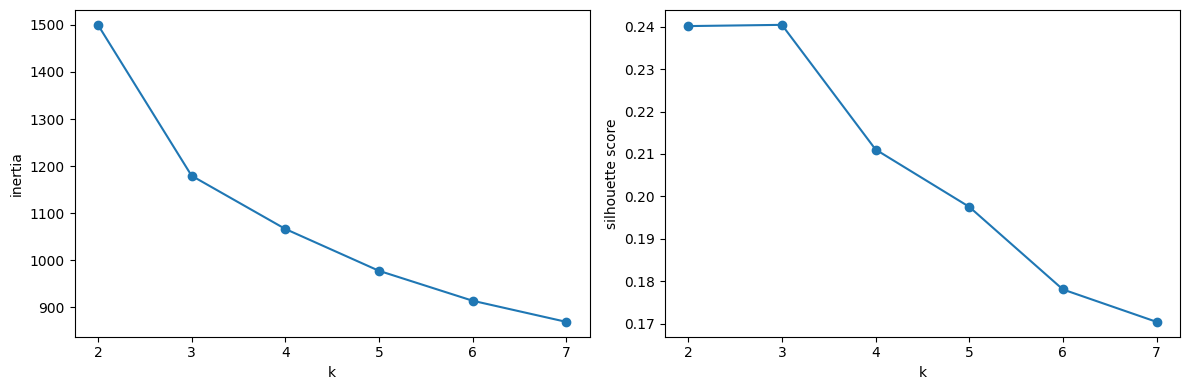

   k      inertia  silhouette
0  2  1500.148458    0.240153
1  3  1179.596778    0.240444
2  4  1066.592122    0.211058
3  5   977.660926    0.197542
4  6   914.073328    0.178068
5  7   869.165950    0.170428


In [ ]:
#k means
ks = range(2, 8)
inertias, silhouette_scores = [], []
for k in ks:
    kmeans = KMeans(n_clusters=k,n_init=20, random_state=0).fit(X)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, kmeans.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o")
ax[0].set_xlabel("k")
ax[0].set_ylabel("inertia")
ax[1].plot(ks, silhouette_scores, marker="o")
ax[1].set_xlabel("k")
ax[1].set_ylabel("silhouette score")
plt.tight_layout();
plt.show()
print(pd.DataFrame({"k": ks, "inertia": inertias, "silhouette": silhouette_scores}))

K-Means: choosing the number of clusters
We ran K-Means for k = 2 to 7 (n_init = 20, random_state = 0) on the same 395 × 17 prepared table. The elbow plot bends gradually with no sharp elbow. The silhouette score is highest at k = 2 and k = 3 (about 0.24 each) and then falls (0.21 at k = 4, 0.20 at k = 5, 0.18 at k = 6). A silhouette near 0.24 means the groups overlap, so we treat the clusters as exploratory patterns, not sharply separated categories.

We chose k = 3. It ties k = 2 for the best silhouette score, but it separates the people into three groups with clearly different characteristics (profiled below), while k = 2 gives only two groups (270 and 125 people). Larger values of k lowered the silhouette score and created very small groups (for example, k = 4 includes a group of only 26 people), which are harder to interpret and trust.

In [ ]:
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
analysis["cluster"] = km.labels_
print(pd.DataFrame(km.cluster_centers_, columns=feature_names).round(2))

   log_income  children_17_under  household_size_from_members  \
0        0.65              -0.49                        -0.52   
1       -1.44              -0.18                        -0.19   
2        0.50               1.12                         1.18   

   housing_group_Doubled up / temporary  housing_group_Other  \
0                                  0.07                 0.01   
1                                  0.10                 0.03   
2                                  0.05                 0.05   

   housing_group_Own home  housing_group_Renting, behind  \
0                    0.03                           0.59   
1                    0.00                           0.49   
2                    0.03                           0.54   

   housing_group_Renting, current  housing_group_Unhoused  \
0                            0.28                    0.02   
1                            0.34                    0.03   
2                            0.26                    0.07 

In [ ]:
profile = analysis.groupby("cluster").agg(
    n=("pid", "size"),
    median_income=("income_monthly", "median"),
    pct_zero_income=("income_monthly", lambda s: (s == 0).mean()),
    avg_children=("children_17_under", "mean"),
    avg_household=("household_size_from_members", "mean"),
    pct_urgent_housing=("urgent_housing_proxy", lambda s: (s == "Yes").mean()),
    pct_being_evicted=("eviction_status", lambda s: (s == "Currently being evicted").mean()),
    median_past_due_rent=("past_due_rent", "median"),
    n_with_rent_data=("past_due_rent", "count"),
    pct_repeat_person=("pid_n_profile_tickets", lambda s: (s > 1).mean()),
).round(2)
profile


,n,median_income,pct_zero_income,avg_children,avg_household,pct_urgent_housing,pct_being_evicted,median_past_due_rent,n_with_rent_data,pct_repeat_person
cluster,,,,,,,,,,
0,181,1420.0,0.00,1.61,2.50,0.29,0.27,1861.0,73,0.06
1,116,0.0,0.99,2.05,3.03,0.23,0.20,1650.0,36,0.07
2,98,1412.5,0.09,3.87,5.27,0.36,0.30,2600.0,44,0.09


In [ ]:
#how each cluster looks by caregory
for col in ["housing_group", "employment_status", "eviction_status"]:
    print(pd.crosstab(analysis["cluster"], analysis[col], normalize="index").round(2), "\n")

housing_group  Doubled up / temporary  Other  Own home  Renting, behind  \
cluster                                                                   
0                                0.07   0.01      0.03             0.59   
1                                0.10   0.03      0.00             0.49   
2                                0.05   0.05      0.03             0.54   

housing_group  Renting, current  Unhoused  
cluster                                    
0                          0.28      0.02  
1                          0.34      0.03  
2                          0.26      0.07   

employment_status  Employed  \
cluster                       
0                      0.36   
1                      0.05   
2                      0.39   

employment_status  Employed, but need more hours and/or different work  Other  \
cluster                                                                         
0                                                                 0.22   0.08   
1  

In [ ]:
 # Name the clusters from what they look like (cluster numbers are arbitrary)
zero_share = analysis.groupby("cluster")["income_monthly"].apply(lambda s: (s == 0).mean())
hh_size    = analysis.groupby("cluster")["household_size_from_members"].mean()
no_income  = zero_share.idxmax()                      # nearly everyone reports $0 income
large      = hh_size.drop(no_income).idxmax()         # biggest households among the rest
small      = [c for c in zero_share.index if c not in (no_income, large)][0]

names = {small: "Smaller households with income",
         no_income: "No reported income, job-seeking",
         large: "Larger households with income"}
order = ["Smaller households with income", "No reported income, job-seeking", "Larger households with income"]
analysis["cluster_name"] = analysis["cluster"].map(names)
analysis["income_per_person"] = analysis["income_monthly"] / analysis["household_size_from_members"]
analysis["employed_any"] = analysis["employment_status"].isin(["Employed", "Employed, but need more hours and/or different work"])

print(analysis["cluster_name"].value_counts()[order])      # expect 181 / 116 / 98

cluster_name
Smaller households with income     181
No reported income, job-seeking    116
Larger households with income       98
Name: count, dtype: int64


Cluster names

The names describe only measured attributes. Cluster numbers from K-Means are arbitrary, so we name each group by its most distinctive traits (profile table above).

Name	People	What stands out
Smaller households with income	181	median income 1,420; about 2.5 people per household
No reported income, job-seeking	116	99% report 0 income; 82% unemployed and wanting work
Larger households with income	98	about 5.3 people and 3.9 children; income per person about $277


In [ ]:
# Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hier_labels = hierarchical.fit_predict(X)

print("Hierarchical cluster sizes:")
print(pd.Series(hier_labels).value_counts().sort_index())

Hierarchical cluster sizes:
0     91
1    118
2    186
Name: count, dtype: int64


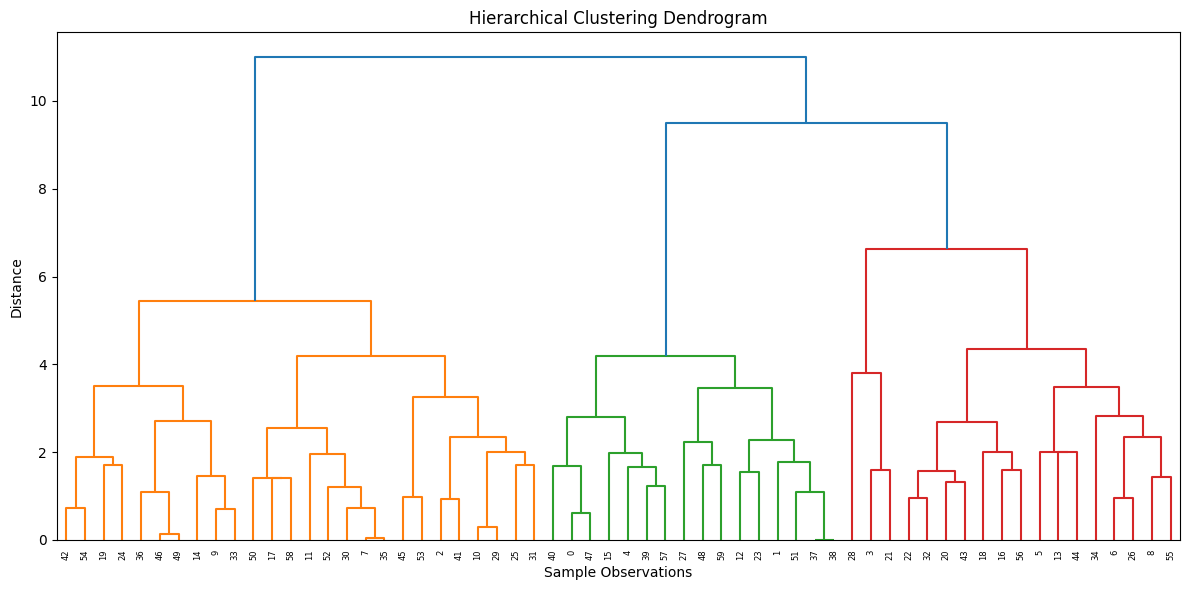

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Create a readable sample of 60 observations
X_sample = X[:60]

# Perform hierarchical clustering
Z = linkage(X_sample, method="ward")

# Plot dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Observations")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import adjusted_rand_score

# Compare K-Means and hierarchical clustering
print("K-Means vs. Hierarchical Clustering")

print(pd.crosstab(
    analysis["cluster"],
    hier_labels,
    rownames=["K-Means"],
    colnames=["Hierarchical"]
))

print("Adjusted Rand Index:",
      round(adjusted_rand_score(
          analysis["cluster"], hier_labels
      ), 3))

K-Means vs. Hierarchical Clustering
Hierarchical   0    1    2
K-Means                   
0              8    0  173
1              0  114    2
2             83    4   11
Adjusted Rand Index: 0.824


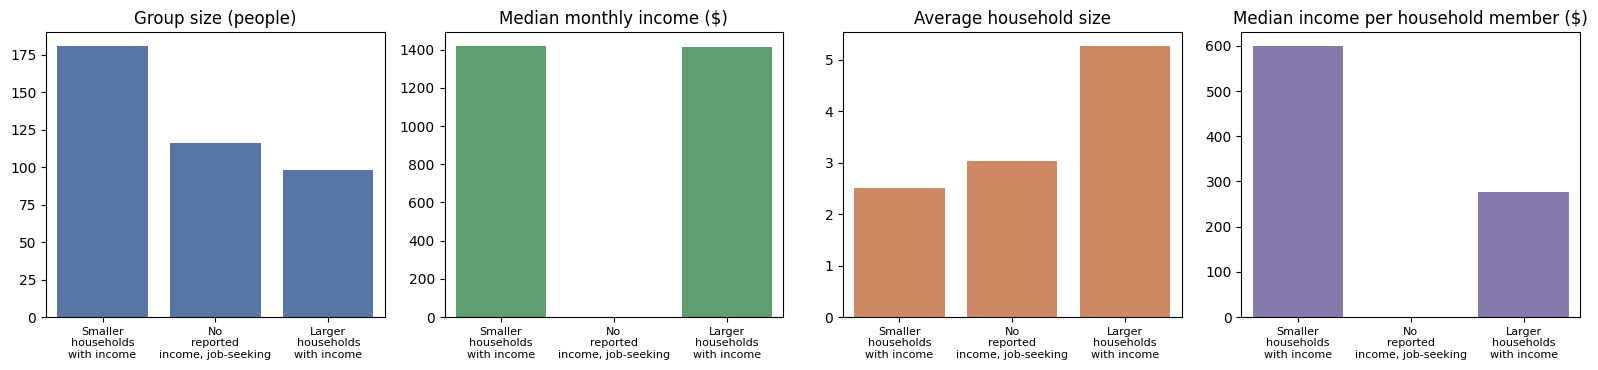

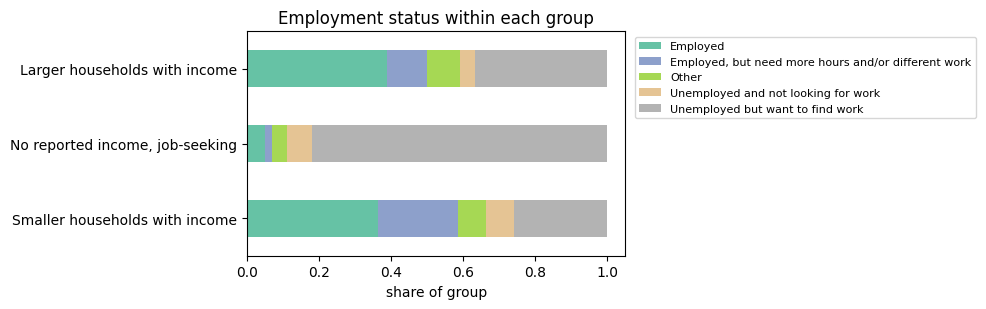

housing_group                    Doubled up / temporary  Other  Own home  \
cluster_name                                                               
Smaller households with income                     0.07   0.01      0.03   
No reported income, job-seeking                    0.10   0.03      0.00   
Larger households with income                      0.05   0.05      0.03   

housing_group                    Renting, behind  Renting, current  Unhoused  
cluster_name                                                                  
Smaller households with income              0.59              0.28      0.02  
No reported income, job-seeking             0.49              0.34      0.03  
Larger households with income               0.54              0.26      0.07  
Housing group vs cluster, chi-square p = 0.056
People in matching groups: 370 of 395
cluster
0    0.96
1    0.98
2    0.85
Name: share matching, by K-Means cluster, dtype: float64


In [ ]:
# ---- Profile plots ----
def wrap(ax):
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([t.get_text().replace(" ", "\n", 2) for t in ax.get_xticklabels()], fontsize=8)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
sns.countplot(data=analysis, x="cluster_name", order=order, ax=ax[0], color="#4c72b0"); ax[0].set_title("Group size (people)")
sns.barplot(data=analysis, x="cluster_name", y="income_monthly", order=order, estimator=np.median, errorbar=None, ax=ax[1], color="#55a868"); ax[1].set_title("Median monthly income ($)")
sns.barplot(data=analysis, x="cluster_name", y="household_size_from_members", order=order, errorbar=None, ax=ax[2], color="#dd8452"); ax[2].set_title("Average household size")
sns.barplot(data=analysis, x="cluster_name", y="income_per_person", order=order, estimator=np.median, errorbar=None, ax=ax[3], color="#8172b3"); ax[3].set_title("Median income per household member ($)")
for a in ax: wrap(a)
plt.tight_layout(); plt.show()

emp = pd.crosstab(analysis["cluster_name"], analysis["employment_status"], normalize="index").loc[order]
emp.plot(kind="barh", stacked=True, figsize=(10, 3.2), colormap="Set2")
plt.title("Employment status within each group"); plt.xlabel("share of group"); plt.ylabel("")
plt.legend(bbox_to_anchor=(1.01, 1), fontsize=8); plt.tight_layout(); plt.show()

# ---- Does housing differ by group? ----
from scipy.stats import chi2_contingency
hous = pd.crosstab(analysis["cluster_name"], analysis["housing_group"], normalize="index").loc[order].round(2)
print(hous)
print("Housing group vs cluster, chi-square p =", round(chi2_contingency(pd.crosstab(analysis["cluster"], analysis["housing_group"]))[1], 3))

# ---- Stability across the two methods ----
ct = pd.crosstab(analysis["cluster"], hier_labels)
matches = sum(ct.max(axis=1))                       # people whose K-Means group maps to its best-matching hierarchical group
print("People in matching groups:", matches, "of", len(analysis))
print((ct.max(axis=1) / ct.sum(axis=1)).round(2).rename("share matching, by K-Means cluster"))

### Comparison of K-Means and Hierarchical Clustering

We compared K-Means and hierarchical clustering using three clusters and the same prepared dataset of 395 people. The Adjusted Rand Index (ARI) was 0.824, indicating strong agreement between the two methods.

Most individuals were grouped similarly across both methods, although some differences appeared in cluster assignments. This suggests that the clustering patterns are reasonably consistent across the two approaches.

However, the clusters are exploratory and do not represent confirmed categories of need or eligibility for assistance. Further analysis is necessary to understand the characteristics of each group.

# Policy Question 1: Different patterns of need
Answer. Yes. K-Means with k = 3 found three groups that are separated mainly by income/employment and household composition, not by housing status.

Smaller households with income (181 people). Median monthly income 1,420, about 2.5 people per household (1.6 children on average), and roughly 600 per household member. 59% are employed (36% employed plus 22% employed but needing more hours or different work).
No reported income, job-seeking (116 people). 99% (115 of 116) reported 0 income and 82% were unemployed but wanted to find work. Only 7% were employed in any form. Average household size is about 3.0.
Larger households with income (98 people). About 5.3 people and 3.9 children per household. Median income (1,413) is almost the same as the smaller-household group, but spread across more people it is only about 277 per household member. 50% are employed in some form.
Housing. Housing and eviction status look similar across the three groups. About half of each group are renting and behind on rent (59%, 49%, 54%), and the overall differences in housing status are not statistically clear (chi-square p = 0.056). Housing instability therefore appears across all three groups instead of defining one of them.

Stability across methods. Hierarchical clustering (Ward linkage, k = 3) agrees strongly with K-Means (Adjusted Rand Index = 0.824), and 370 of 395 people (94%) fall in matching groups. The no-income group is the most stable (114 of 116) and the larger-household group the least stable (83 of 98; 11 and 4 people move to the other two groups).

Caution. The silhouette score is only about 0.24, so the groups overlap. Income and household size were clustering inputs, so differences in those are expected. These groups describe patterns in the data and are not categories of need or eligibility.

In [ ]:
q1 = analysis.groupby("cluster_name").agg(
    people=("pid", "size"),
    median_income=("income_monthly", "median"),
    pct_zero_income=("income_monthly", lambda s: (s == 0).mean()),
    avg_household=("household_size_from_members", "mean"),
    avg_children=("children_17_under", "mean"),
    median_income_per_person=("income_per_person", "median"),
    pct_employed_any=("employed_any", "mean"),
    pct_unemployed_want_work=("employment_status", lambda s: (s == "Unemployed but want to find work").mean()),
    pct_renting_behind=("housing_group", lambda s: (s == "Renting, behind").mean()),
).loc[order].round(2)
q1.T

cluster_name,Smaller households with income,"No reported income, job-seeking",Larger households with income
people,181.00,116.00,98.00
median_income,1420.00,0.00,1412.50
pct_zero_income,0.00,0.99,0.09
avg_household,2.50,3.03,5.27
avg_children,1.61,2.05,3.87
median_income_per_person,600.00,0.00,276.53
pct_employed_any,0.59,0.07,0.50
pct_unemployed_want_work,0.26,0.82,0.37
pct_renting_behind,0.59,0.49,0.54


Policy Question 2: Overlapping pressures

In [ ]:
# ---- Q2: which pressures appear together? (within-cluster comparisons) ----
q2 = analysis.groupby("cluster_name").agg(
    n=("pid", "size"),
    pct_zero_income=("income_monthly", lambda s: (s == 0).mean()),
    pct_employed_any=("employed_any", "mean"),
    median_income_per_person=("income_per_person", "median"),
    pct_renting_behind=("housing_group", lambda s: (s == "Renting, behind").mean()),
    pct_being_evicted=("eviction_status", lambda s: (s == "Currently being evicted").mean()),
    pct_urgent_housing=("urgent_housing_proxy", lambda s: (s == "Yes").mean()),
    n_with_rent_data=("past_due_rent", "count"),
    median_past_due_rent=("past_due_rent", "median"),
    n_high_arrears=("high_arrears_3000", lambda s: int((s == 1).sum())),
    pct_high_arrears=("high_arrears_3000", "mean"),      # only among people WITH rent data
).loc[order]
q2["pct_with_rent_data"] = q2["n_with_rent_data"] / q2["n"]
q2.round(2).T

cluster_name,Smaller households with income,"No reported income, job-seeking",Larger households with income
n,181.00,116.00,98.00
pct_zero_income,0.00,0.99,0.09
pct_employed_any,0.59,0.07,0.50
median_income_per_person,600.00,0.00,276.53
pct_renting_behind,0.59,0.49,0.54
pct_being_evicted,0.27,0.20,0.30
pct_urgent_housing,0.29,0.23,0.36
n_with_rent_data,73.00,36.00,44.00
median_past_due_rent,1861.00,1650.00,2600.00
n_high_arrears,18.00,7.00,21.00


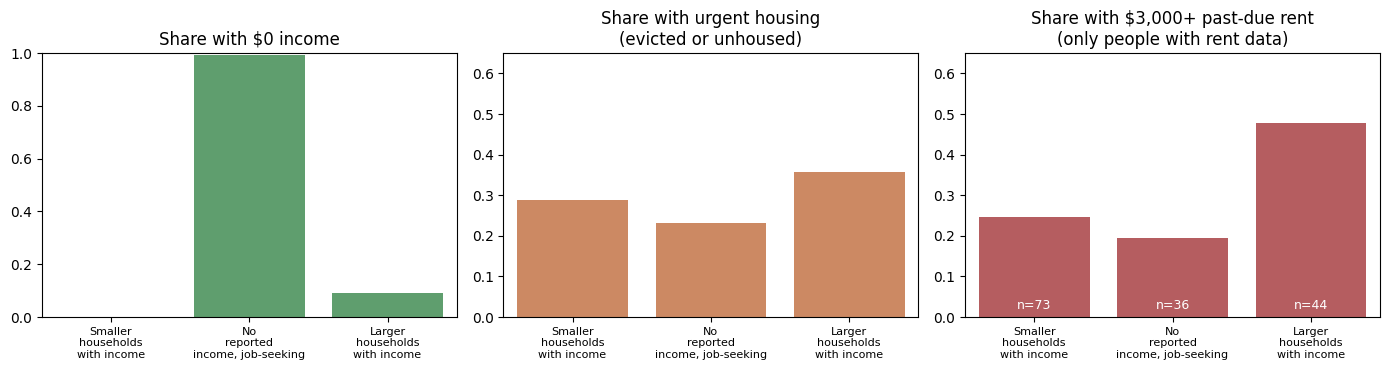

high_arrears_3000                0.0  1.0
cluster_name                             
Smaller households with income    55   18
No reported income, job-seeking   29    7
Larger households with income     23   21
High arrears vs cluster (rent-data people only): chi-square p = 0.009
Urgent housing vs cluster: p = 0.27
Currently being evicted vs cluster: p = 0.217


In [ ]:
# ---- Q2 plot ----
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.barplot(data=analysis, x="cluster_name", y="income_monthly", order=order, estimator=lambda s: (s == 0).mean(), errorbar=None, ax=ax[0], color="#55a868"); ax[0].set_title("Share with $0 income")
d = analysis.assign(urgent=(analysis["urgent_housing_proxy"] == "Yes").astype(int))
sns.barplot(data=d, x="cluster_name", y="urgent", order=order, errorbar=None, ax=ax[1], color="#dd8452"); ax[1].set_title("Share with urgent housing\n(evicted or unhoused)")
r = analysis[analysis["high_arrears_3000"].notna()]
sns.barplot(data=r, x="cluster_name", y="high_arrears_3000", order=order, errorbar=None, ax=ax[2], color="#c44e52"); ax[2].set_title("Share with $3,000+ past-due rent\n(only people with rent data)")
for i, a in enumerate(ax):
    wrap(a); a.set_ylim(0, 1.0 if i == 0 else 0.65)
for i, n in enumerate(order): ax[2].text(i, 0.02, f"n={int((r['cluster_name'] == n).sum())}", ha="center", color="white", fontsize=9)
plt.tight_layout(); plt.show()

# ---- Are the differences likely to be chance? ----
ct_arrears = pd.crosstab(r["cluster_name"], r["high_arrears_3000"]).loc[order]
print(ct_arrears)
print("High arrears vs cluster (rent-data people only): chi-square p =", round(chi2_contingency(ct_arrears)[1], 3))
print("Urgent housing vs cluster: p =", round(chi2_contingency(pd.crosstab(analysis["cluster"], analysis["urgent_housing_proxy"]))[1], 3))
print("Currently being evicted vs cluster: p =", round(chi2_contingency(pd.crosstab(analysis["cluster"], analysis["eviction_status"] == "Currently being evicted"))[1], 3))

Answer. The clearest combination is in the larger-household group: an income similar to the smaller-household group spread across many more people (lowest income per person), together with the highest share of large past-due rent.

Past-due rent of 3,000 or more (people with rent data): 48% of larger households (21 of 44), compared with 25% (18 of 73) of smaller households and 19% (7 of 36) of the no-income group. This difference is unlikely to be chance (chi-square p = 0.009). Median past-due rent is 2,600, 1,861 and 1,650 respectively.
Income alone did not protect against arrears. The smaller and larger groups have almost the same median income (about 1,415), yet larger households are far more likely to be behind. This fits their lower income per household member (about 277 vs 600), but we cannot say income per person causes the arrears.
Employment did not explain the difference. 59% of smaller and 50% of larger households have some employment, but their arrears differ a lot.
The no-income group had the lowest arrears (19%, 7 of 36), which is surprising. Only 31% of this group (36 of 116) have rent data, compared with 40% and 45% in the other groups, so this may reflect who completed the rent form.
Urgent housing and eviction (29%, 23%, 36% and 27%, 20%, 30%) do not differ clearly between groups (p = 0.27 and 0.22), so we do not claim a difference.
Limits. Rent data exists for only 153 of 395 people (39%), so arrears findings describe people who completed the rent form. These are associations, not causes.

### Policy Question 3: Repeat Needs and Missing Information

In [ ]:
# Repeat contacts by K-Means cluster
analysis["repeat_contact"] = (
    analysis["pid_n_profile_tickets"] > 1
)

repeat_summary = analysis.groupby("cluster")["repeat_contact"].agg(
    ["sum", "count", "mean"]
)

repeat_summary["percentage"] = (
    repeat_summary["mean"] * 100
).round(1)

print(repeat_summary)

         sum  count      mean  percentage
cluster                                  
0         10    181  0.055249         5.5
1          8    116  0.068966         6.9
2          9     98  0.091837         9.2


### Policy Question 3: Repeat Contacts

We examined repeat contacts across the three K-Means clusters. Cluster 0 had 10 repeat contacts out of 181 people (5.5%), Cluster 1 had 8 out of 116 (6.9%), and Cluster 2 had 9 out of 98 (9.2%).

Cluster 2 had the highest percentage of repeat contacts, suggesting that repeat contact may be somewhat more common in this group. However, the differences were small, and only 27 of the 395 people had multiple profile tickets.

Repeat contacts do not necessarily mean that assistance was unsuccessful or that a household experienced ongoing instability. More information about the timing of contacts, reasons for returning, assistance received, and subsequent outcomes would be needed to understand these patterns.

In [ ]:
# Inspect care-path sub-ticket columns
print(subs.columns.tolist())

['issue_key', 'parent_issue_key', 'parent_in_file', 'pid', 'care_path_type', 'created_date', 'case_status', 'case_status_category', 'pid_matches_parent', 'care_path_group']


In [ ]:
# Check how many care-path sub-tickets have parent profiles

print("Total sub-tickets:", len(subs))

print("Parent profiles found:",
      subs["parent_in_file"].value_counts(dropna=False))

print("Care-path types:")
print(subs["care_path_type"].value_counts())

Total sub-tickets: 213
Parent profiles found: parent_in_file
Yes    200
No      13
Name: count, dtype: int64
Care-path types:
care_path_type
Rent Assistance Care Path                     112
House Navigation Care Path                     24
Basic Supplies                                 17
Utility Care Path                              12
Other                                           9
Legal Assistance Care Path                      7
Food Care Path                                  5
Transportation Care Path                        5
Digital Access                                  3
Eviction Prevention Care Path                   3
Medical Costs or Bills                          3
Child Care Path                                 2
Play Cousins Care Path                          2
Pregnancy/Postpartum Care Path                  2
Healthcare Navigation Path                      2
Foreclosure Prevention/Mortgage Assistance      1
Care Plan                                       1
Case Mana

In [ ]:
# Count linked care-path sub-tickets across all profiles for each person
care_by_pid = profiles.groupby("pid")["n_care_path_subtickets"].sum()

analysis["care_subtickets"] = (
    analysis["pid"].map(care_by_pid).fillna(0)
)

care_summary = analysis.groupby("cluster")["care_subtickets"].agg(
    total_subtickets="sum",
    people="count",
    people_with_subtickets=lambda s: (s > 0).sum(),
    average_subtickets="mean"
)

care_summary["pct_with_subtickets"] = (
    care_summary["people_with_subtickets"]
    / care_summary["people"] * 100
).round(1)

print(care_summary.round(2))

         total_subtickets  people  people_with_subtickets  average_subtickets  \
cluster                                                                         
0                      88     181                      72                0.49   
1                      66     116                      51                0.57   
2                      46      98                      39                0.47   

         pct_with_subtickets  
cluster                       
0                       39.8  
1                       44.0  
2                       39.8  


We also compared linked care-path sub-tickets across the three clusters. Cluster 0 had 72 of 181 people with at least one linked sub-ticket (39.8%), Cluster 1 had 51 of 116 (44.0%), and Cluster 2 had 39 of 98 (39.8%). Cluster 1 had the highest percentage and the highest average number of sub-tickets per person at 0.57, but the differences between clusters were relatively small.

Of the 213 care-path sub-tickets in the file, 200 could be linked to a parent profile and 13 could not. Because some sub-ticket PIDs differ from the PID of their parent profile, we relied on the parent-profile relationship rather than assuming that PID values always matched.

These results do not tell us whether a person was experiencing an immediate crisis, recurring instability, or whether assistance improved their situation. To evaluate that, SLCM would need information about the timing and reason for each contact, the services provided, and follow-up outcomes after assistance.

### Policy Question 4: SLCM Program and Policy Implications

Our first recommendation is for SLCM to investigate whether households showing greater housing pressure could benefit from more coordinated housing-stabilization follow-up. Cluster 2 had the highest urgent-housing rate at 36%, the highest eviction rate at 30%, and a median reported past-due rent of $2,600 among the 44 people in that cluster with rent data. This cluster also had the largest average household size at 5.27 people. The urgent-housing and eviction differences between clusters were small and not statistically clear, so this recommendation rests mainly on the rent-arrears pattern (48% of people with rent data owed 3,000 or more, compared with 25% and 19% in the other clusters).These findings could help SLCM explore how housing assistance connects with its Reconnect and longer-term stabilization work. A major limitation is that past-due rent was missing for many people, so the rent results do not represent the entire cluster.

Our second recommendation is for SLCM to investigate employment and income-support services for households with very low reported income. Cluster 1 had a median monthly income of 0, 99% reported 0 income, and 82% were unemployed but wanted to find work. SLCM could explore whether employment navigation, workforce connections, or income-support referrals could complement its Rethink and Rebuild work. However, the data does not explain why income was $0, how long unemployment lasted, or what barriers people faced.

These clusters should not be used by themselves to determine who receives assistance. Clustering is exploratory, the groups are created from a limited set of recorded variables, and some information is missing or unknown. Individual circumstances and additional information should remain part of any service decision.

### What Did We Learn?

Our strongest discovery was that the intake records did show meaningful patterns of need, especially around  income, employment, and household size. One cluster of larger households had the highest share with large past-due rent, while another cluster showed very low reported income and a high percentage of people who were unemployed but wanted to work.

One result that stood out was how similar the K-Means and hierarchical clustering results were. The Adjusted Rand Index was 0.824, which showed strong agreement between the two methods. However, the cluster assignments were not exactly the same, showing that clustering results can depend on the method being used.

The data cannot tell us whether a household was experiencing a short-term crisis or long-term instability, and it cannot tell us whether SLCM assistance improved the household’s situation. We also cannot assume that repeated contacts mean that previous assistance failed.

For future analysis, SLCM could collect more consistent follow-up information, such as the type of assistance provided, the date of service, the reason for returning, and whether the household’s situation improved after assistance. This would make it easier to connect the patterns found in the clusters to actual outcomes over time. The clusters in this analysis should be treated as exploratory patterns, not as validated risk categories.